# LD1 vs PC1 (supplementary): is the individuality axis just the main axis of variation?

Answers the review question *"how different is LD1 from simple variation in the data?"*. Same 260 sessions × 360 syllable features as the saved embedding; PCA is fit to the same matrix with no labels.

| panel | what |
|---|---|
| A | LD1 vs PC1, one point per session, mouse means on top |
| B | held-out repeatability per axis (fig_lda panel C metric): LDA axes, principal components, random directions, shuffled-label LDA axes |
| C | syllable use along PC1 (fig_ld1 B arithmetic) |
| D | syllable use along LD1, for comparison |
| E | what PC1 means in occupancy: sessions in the bottom vs top PC1 quintile |

**Read with.** PCA is fit on the *covariance* of the raw occupancies, so features with large session-to-session variance (whisking, licking) dominate it. On z-scored features PC1 is a different axis (printed below). LDA is invariant to rescaling. The held-out R² uses a fixed shrinkage (0.5, the embedding's) rather than `lda_shrinkage_figures`' inner-CV choice, so the LDA curve sits close to, but is not identical with, fig_lda C.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from datetime import date
from scipy import linalg
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

FIGDIR = pathlib.Path.cwd().resolve()
while not (FIGDIR / 'fig_layout.py').exists() and FIGDIR != FIGDIR.parent:
    FIGDIR = FIGDIR / 'figure_generation' if (FIGDIR / 'figure_generation').exists() else FIGDIR.parent
PI = FIGDIR.parent
for p in [str(PI), str(FIGDIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)
try:
    import numpy._core.numeric  # noqa: F401
except ModuleNotFoundError:     # the LDA file was pickled under numpy 2
    import numpy.core.numeric, numpy.core.multiarray
    sys.modules['numpy._core.numeric'], sys.modules['numpy._core.multiarray'] = np.core.numeric, np.core.multiarray
import paper_style as ps
import fig_layout as fl
ps.use('paper')
ps.use_paw_states('uniform')
FIG = 'fig_ld1_vs_pc1'

LDA_FILE = PI / 'clustering' / 'data_files' / 'mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026'   # as fig_ld1
SYLLABLE_FILE = next(f for f in [PI / 'data' / '8_k_10_bin_syllables_02-10-2026',                  # the file the LDA was fit on
                                 PI / 'clustering' / 'data_files' / '8_k_10_bin_syllables_02-10-2026'] if f.exists())
CACHE = FIGDIR / 'cache' / 'ld1_vs_pc1_heldout.pkl'   # B takes ~2 min; delete to recompute
SHRINKAGE = 0.5         # the embedding's
N_PER_MOUSE = 3         # balanced training draw, as lda_shrinkage
K = 20                  # axes scored in B
N_BOOT = 2000           # B: bootstrap over mice
N_PERMS = 1000          # C/D: permutation null, as fig_ld1
SEED = 0

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Data

Session occupancy as in `fig_ld_syllables`. Two versions of the same numbers:
* `X`: the LDA's design matrix, in the syllable file's own paw numbering with raw paw state 1 dropped as the reference, exactly as `lda_shrinkage.binarize`. The refit below must reproduce the saved LD1.
* `SESS_OCC`: all 10 syllables per bin in the display (uniform) numbering, for the plots.

In [2]:
lda = pd.read_pickle(LDA_FILE)
syl = pd.read_parquet(SYLLABLE_FILE)
syl['session'] = syl['sample'].str[:36]
syl = syl[syl['session'].isin(lda['session'])]
EPOCHS = ps.EPOCH_NAMES
trials = (syl.pivot(index=['mouse_name', 'session', 'sample'], columns='broader_label', values='binned_sequence')
          .reset_index().dropna(subset=EPOCHS))
raw_codes = np.vstack([np.hstack(r) for r in trials[EPOCHS].to_numpy()]).astype(float)
sess_idx = trials['session'].to_numpy()
order = lda['session'].to_numpy()


def occupancy(codes):
    paw, whisk, lick = ps.decode_syllables(codes)
    occ = np.stack([np.where(np.isnan(paw), np.nan, paw == k) for k in range(ps.N_PAW_STATES)] + [whisk, lick], axis=-1)
    with np.errstate(invalid='ignore'):
        return np.stack([np.nanmean(occ[sess_idx == s], axis=0) for s in order])   # (sessions, bins, 10)


SESS_OCC = occupancy(ps.paw_codes(raw_codes))
N_BINS = SESS_OCC.shape[1]
X = np.delete(occupancy(raw_codes), 1, axis=2).reshape(len(order), -1)          # lda_shrinkage.binarize layout
y = pd.factorize(lda['mouse_name'])[0]
FEAT_LABEL = [ps.paw_label(k) for k in range(ps.N_PAW_STATES)] + ['Whisk', 'Lick']
FEAT_COLORS = ps.SYLLABLE_COLORS


def fit_mouse_weighted(Xt, yt, s):
    """lda_shrinkage's embedding: between-mouse scatter of the mouse means (each counted once),
    within-mouse scatter pooled over sessions and shrunk toward a scaled identity."""
    classes = np.unique(yt)
    M = np.stack([Xt[yt == c].mean(axis=0) for c in classes])
    grand = M.mean(axis=0)
    Sb = np.cov((M - grand).T, bias=True)
    R = Xt - M[np.searchsorted(classes, yt)]
    Sw = R.T @ R / (len(Xt) - len(classes))
    Sw = (1 - s) * Sw + s * np.trace(Sw) / len(Sw) * np.eye(len(Sw))
    ev, V = linalg.eigh(Sb, Sw)
    o = np.argsort(ev)[::-1][:len(classes) - 1]
    return V[:, o], grand


W, grand = fit_mouse_weighted(X, y, SHRINKAGE)
LD1 = lda[0].to_numpy(float)
r_check = np.corrcoef((X - grand) @ W[:, 0], LD1)[0, 1]
assert abs(r_check) > 0.999, f'refit does not reproduce the saved LD1 (r = {r_check:.4f})'
print(f'{SYLLABLE_FILE.name}: {X.shape[0]} sessions x {X.shape[1]} features, {y.max() + 1} mice; '
      f'refit LD1 vs saved r = {r_check:+.4f}')

8_k_10_bin_syllables_02-10-2026: 260 sessions x 360 features, 56 mice; refit LD1 vs saved r = +1.0000


## How LD1 relates to the principal components

PC1's sign is arbitrary; it is oriented so that it correlates positively with LD1.

In [3]:
pca = PCA().fit(X)
PC = pca.transform(X)
EVR = pca.explained_variance_ratio_
sign = np.sign(np.corrcoef(PC[:, 0], LD1)[0, 1])
PC1 = sign * PC[:, 0]


def r2_from(P, v):
    A = np.c_[np.ones(len(v)), P]
    res = v - A @ np.linalg.lstsq(A, v, rcond=None)[0]
    return 1 - (res ** 2).sum() / ((v - v.mean()) ** 2).sum()


r_pc = [np.corrcoef(PC[:, k], LD1)[0, 1] for k in range(10)]
w1 = W[:, 0] / np.linalg.norm(W[:, 0])
ld1_var_share = np.var(X @ w1, ddof=1) / np.trace(np.cov(X.T))
print('variance share PC1..5:', np.round(EVR[:5], 3))
print('r(LD1, PCk), k = 1..10:', np.round(np.abs(r_pc), 2))
print('R^2 of LD1 from the first k PCs:', {k: round(r2_from(PC[:, :k], LD1), 3) for k in (1, 3, 5, 10, 20)})
print(f'variance along the LD1 direction: {ld1_var_share:.3f} of the total '
      f'(PC1 {EVR[0]:.3f}; as large as PC{int((EVR > ld1_var_share).sum()) + 1})')

Xz = (X - X.mean(0)) / (X.std(0) + 1e-12)
PCz = PCA(1).fit_transform(Xz)[:, 0]
print(f'PCA on z-scored features instead: PC1 r with LD1 = {np.corrcoef(PCz, LD1)[0, 1]:+.2f}')

# mouse / session split of each axis, in sample (LD axes are fit to maximise it, so theirs is optimistic)
def session_share(z):
    mm = pd.Series(z).groupby(y).transform('mean').to_numpy()
    return ((z - mm) ** 2).sum() / ((z - z.mean()) ** 2).sum()
mm_all = pd.DataFrame(X).groupby(y).transform('mean').to_numpy()
print(f'within-mouse (session-to-session) share, in sample: all 360 features '
      f'{((X - mm_all) ** 2).sum() / ((X - X.mean(0)) ** 2).sum():.2f}, '
      f'PC1 {session_share(PC1):.2f}, PC2 {session_share(PC[:, 1]):.2f}, LD1 {session_share(LD1):.2f}')

variance share PC1..5: [0.282 0.155 0.115 0.076 0.051]
r(LD1, PCk), k = 1..10: [0.78 0.3  0.14 0.27 0.27 0.06 0.05 0.21 0.08 0.08]
R^2 of LD1 from the first k PCs: {1: 0.605, 3: 0.713, 5: 0.861, 10: 0.923, 20: 0.989}
variance along the LD1 direction: 0.041 of the total (PC1 0.282; as large as PC7)
PCA on z-scored features instead: PC1 r with LD1 = -0.43
within-mouse (session-to-session) share, in sample: all 360 features 0.29, PC1 0.15, PC2 0.38, LD1 0.06


## Held-out repeatability per axis (panel B)

fig_lda panel C's metric, leave-one-session-out: $R^2_k = 1 - \sum (z_k - \mu_{\text{own},k})^2 / \sum (z_k - \bar\mu_k)^2$ over held-out sessions, where centroids come from the training sessions only. Every basis is fit on the same balanced training draw (≤ 3 sessions per mouse):
* **LDA**: shrinkage LDA, the paper's axes.
* **PCA**: label-free principal components of the training sessions.
* **Random**: K random orthonormal directions, redrawn every fold.
* **Shuffled LDA**: LDA fit to permuted mouse labels, then scored with the true ones.

Bands (LDA and PCA only): 95% bootstrap over mice.

In [4]:
BASES = ['lda', 'pca', 'rand', 'lda_shuf']
if CACHE.exists():
    HELD = pd.read_pickle(CACHE)
    print('loaded', CACHE.relative_to(PI))
else:
    rng = np.random.default_rng(SEED)
    n, p = X.shape
    n_mice = y.max() + 1
    acc = {b: {'res2': np.zeros((n, K)), 'dev2': np.zeros((n, K))} for b in BASES}

    def balanced_draw(y_sub):
        return np.concatenate([rng.choice(np.where(y_sub == m)[0], min(N_PER_MOUSE, (y_sub == m).sum()), replace=False)
                               for m in np.unique(y_sub)])

    def fit_lda(Xt, yt):
        return LinearDiscriminantAnalysis(solver='eigen', shrinkage=SHRINKAGE,
                                          priors=np.ones(n_mice) / n_mice).fit(Xt, yt).scalings_[:, :K]

    for t in range(n):
        tr = np.setdiff1d(np.arange(n), t)
        sel = tr[balanced_draw(y[tr])]
        Xtr, ytr = X[sel], y[sel]
        q = PCA(K).fit(Xtr)
        proj = {'lda': fit_lda(Xtr, ytr), 'lda_shuf': fit_lda(Xtr, rng.permutation(ytr)),
                'rand': np.linalg.qr(rng.standard_normal((p, K)))[0], 'pca': q.components_.T}
        classes = np.unique(ytr)
        own = np.searchsorted(classes, y[t])
        for b, P in proj.items():
            Z = (Xtr - q.mean_) @ P
            M = np.stack([Z[ytr == c].mean(0) for c in classes])
            z = (X[t] - q.mean_) @ P
            acc[b]['res2'][t] = (z - M[own]) ** 2
            acc[b]['dev2'][t] = (z - M.mean(0)) ** 2

    mice = np.unique(y)
    groups = [np.where(y == m)[0] for m in mice]
    HELD = {}
    for b in BASES:
        r2 = lambda idx: 1 - acc[b]['res2'][idx].sum(0) / acc[b]['dev2'][idx].sum(0)
        boot = np.stack([r2(np.concatenate([groups[i] for i in rng.integers(0, len(mice), len(mice))]))
                         for _ in range(N_BOOT)])
        HELD[b] = {'r2': r2(np.arange(n)), 'lo': np.percentile(boot, 2.5, 0), 'hi': np.percentile(boot, 97.5, 0)}
    CACHE.parent.mkdir(exist_ok=True)
    pd.to_pickle(HELD, CACHE)
    print('wrote', CACHE.relative_to(PI))

for b in BASES:
    h = HELD[b]
    print(f'{b:9s} axis 1-5: ' + '  '.join(f'{e:.2f} [{l:.2f}, {u:.2f}]' for e, l, u in zip(h['r2'][:5], h['lo'][:5], h['hi'][:5])))

loaded figure_generation/cache/ld1_vs_pc1_heldout.pkl
lda       axis 1-5: 0.78 [0.66, 0.85]  0.69 [0.56, 0.78]  0.68 [0.55, 0.77]  0.63 [0.51, 0.71]  0.61 [0.47, 0.72]
pca       axis 1-5: 0.75 [0.61, 0.84]  0.33 [0.14, 0.49]  0.65 [0.48, 0.76]  0.48 [0.30, 0.63]  0.48 [0.32, 0.60]
rand      axis 1-5: 0.60 [0.49, 0.69]  0.58 [0.46, 0.66]  0.47 [0.32, 0.59]  0.49 [0.28, 0.64]  0.49 [0.32, 0.62]
lda_shuf  axis 1-5: 0.44 [0.30, 0.54]  0.48 [0.35, 0.58]  0.29 [0.08, 0.46]  0.38 [0.22, 0.51]  0.46 [0.31, 0.57]


## Syllable use along PC1 and LD1 (panels C, D)

fig_ld1 panel B's arithmetic: per (trial bin, syllable), the Pearson r across sessions between the session's occupancy and its score on the axis. Grey band: permutation null (scores shuffled across sessions, 2.5–97.5%, widest over the syllables). Lines are bold outside the null.

In [5]:
def colwise_r(Mx, v):
    Mc = np.nan_to_num(Mx - np.nanmean(Mx, axis=0))
    vc = v - v.mean()
    return (Mc.T @ vc) / (np.sqrt((Mc ** 2).sum(axis=0)) * np.sqrt((vc ** 2).sum()))


flat = SESS_OCC.reshape(len(order), -1)
AXES = {'PC1': PC1, 'LD1': LD1}
STRUCT, NULL_LO, NULL_HI = {}, {}, {}
for i, (name, score) in enumerate(AXES.items()):
    with np.errstate(invalid='ignore'):
        STRUCT[name] = colwise_r(flat, score).reshape(N_BINS, -1)
        rng = np.random.default_rng(SEED + i)
        null = np.stack([colwise_r(flat, rng.permutation(score)).reshape(N_BINS, -1) for _ in range(N_PERMS)])
    NULL_LO[name], NULL_HI[name] = np.nanpercentile(null, [2.5, 97.5], axis=0)
s_pc, s_ld = STRUCT['PC1'].ravel(), STRUCT['LD1'].ravel()
ok = ~np.isnan(s_pc) & ~np.isnan(s_ld)
print(f'PC1 and LD1 load on the same bins and syllables: r between their structure coefficients = '
      f'{np.corrcoef(s_pc[ok], s_ld[ok])[0, 1]:.2f}')

PC1 and LD1 load on the same bins and syllables: r between their structure coefficients = 0.79


## PC1 in words (panel E)

Mean occupancy, bin by bin, of the sessions in the bottom and top PC1 quintiles. The table lists, per epoch and syllable, the occupancy in each quintile and the r with PC1.

In [6]:
q = pd.qcut(PC1, 5, labels=False)
LOW, HIGH = np.nanmean(SESS_OCC[q == 0], axis=0), np.nanmean(SESS_OCC[q == 4], axis=0)
ep = np.repeat(ps.EPOCH_SHORT, N_BINS // 4)
rows = []
for f in range(10):
    for e in ps.EPOCH_SHORT:
        m = ep == e
        rows.append({'syllable': FEAT_LABEL[f], 'epoch': e, 'low PC1': LOW[m, f].mean(), 'high PC1': HIGH[m, f].mean(),
                     'r with PC1': np.nanmean(STRUCT['PC1'][m, f])})
WORDS = pd.DataFrame(rows)
WORDS['high - low'] = WORDS['high PC1'] - WORDS['low PC1']
print(WORDS.reindex(WORDS['r with PC1'].abs().sort_values(ascending=False).index).head(14).round(2).to_string(index=False))
print(f'\nmice: {pd.Series(PC1).groupby(lda["mouse_name"].to_numpy()).mean().sort_values().index[[0, -1]].tolist()} '
      'are the lowest / highest on PC1')

      syllable   epoch  low PC1  high PC1  r with PC1  high - low
         Whisk   Pre-Q     0.28      0.73        0.90        0.45
         Whisk Quiesc.     0.13      0.55        0.84        0.42
         Whisk  Choice     0.60      0.88        0.62        0.28
          Lick   Pre-Q     0.02      0.15        0.55        0.13
          Lick Quiesc.     0.00      0.10        0.54        0.10
          Lick  Choice     0.07      0.24        0.54        0.17
          Lick     ITI     0.32      0.64        0.51        0.32
         Whisk     ITI     0.78      0.92        0.43        0.14
         Paw 0  Choice     0.12      0.05       -0.35       -0.07
Paw 3  (right)  Choice     0.12      0.24        0.32        0.11
Paw 3  (right) Quiesc.     0.00      0.02        0.32        0.01
Paw 3  (right)   Pre-Q     0.02      0.06        0.31        0.04
         Paw 0 Quiesc.     0.18      0.11       -0.30       -0.08
Paw 6  (right)  Choice     0.07      0.10        0.21        0.03

mice: ['C

## The figure

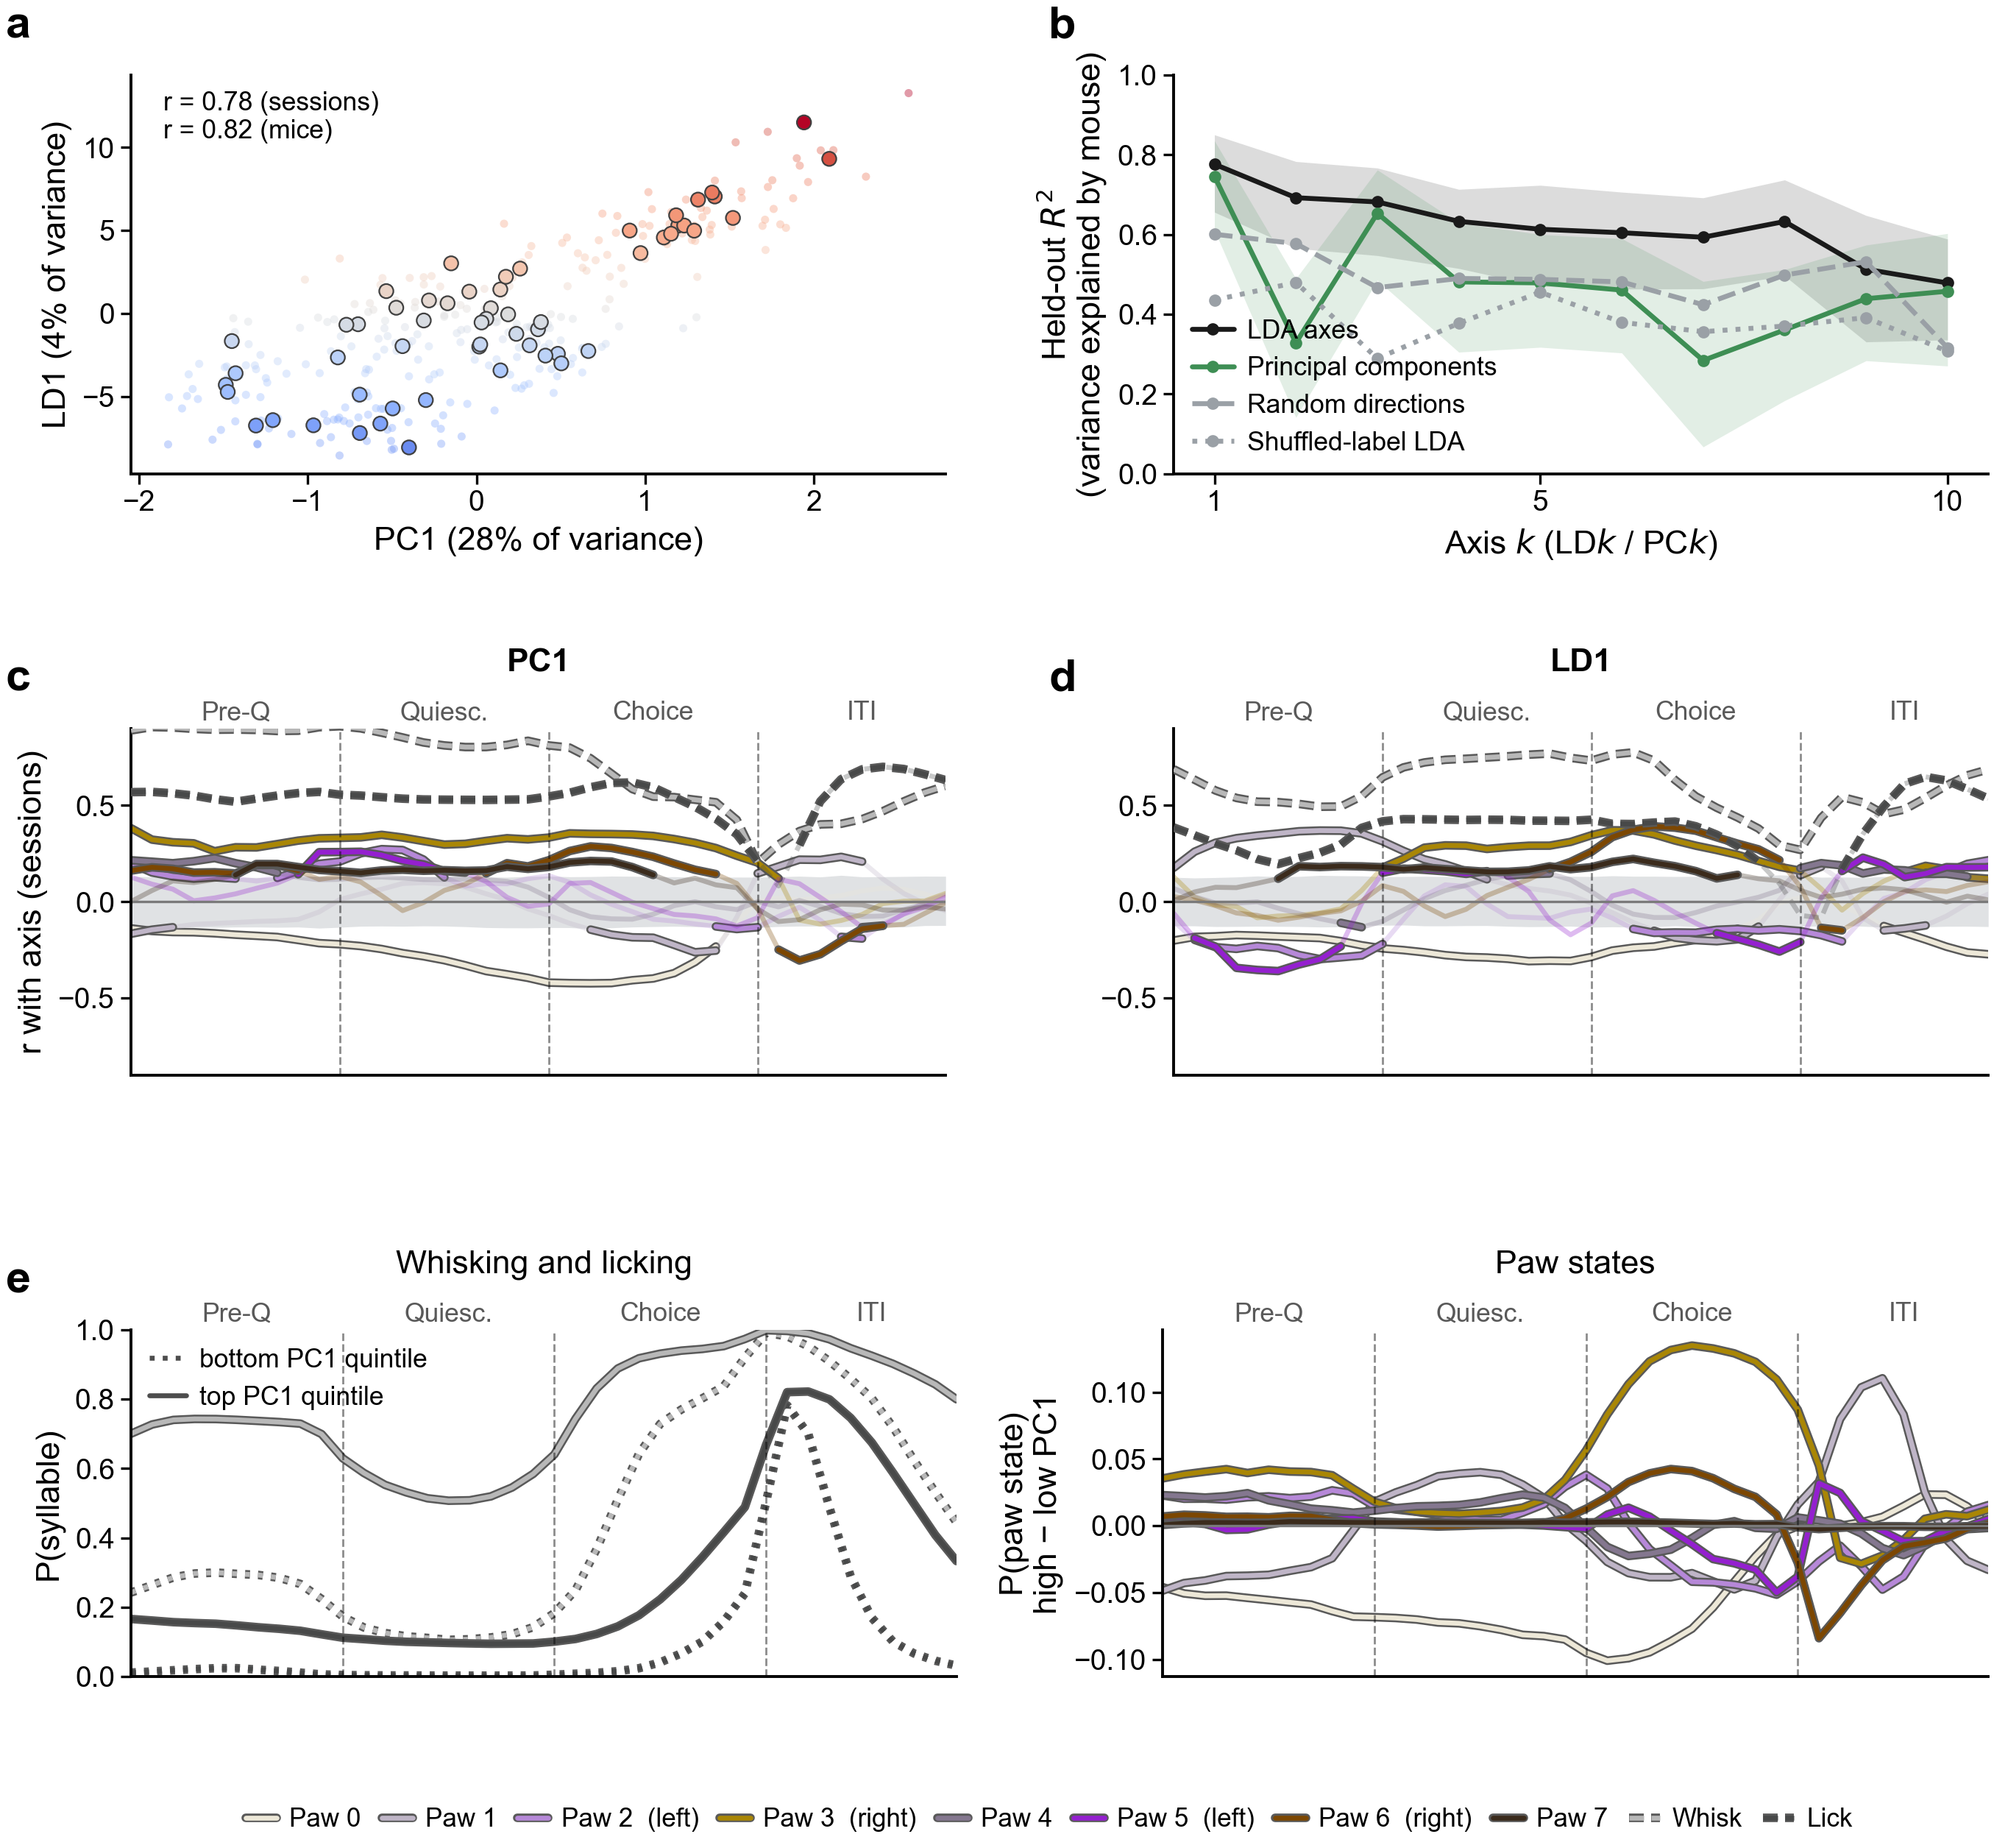

wrote figure_generation/figures/fig_ld1_vs_pc1_03-11-2026.svg


wrote figure_generation/figures/fig_ld1_vs_pc1.pdf


wrote figure_generation/figures/fig_ld1_vs_pc1.png


In [7]:
OUTLINE = [pe.Stroke(linewidth=plt.rcParams['lines.linewidth'] + 0.9, foreground='0.35'), pe.Normal()]
LS = {f: ((0, (3, 1.5)) if f >= 8 else '-') for f in range(10)}   # whisk / lick dashed, as fig_ld_syllables
BASE_STYLE = {'lda': ('LDA axes', '0.1', '-'), 'pca': ('Principal components', '#3E8E54', '-'),
              'rand': ('Random directions', ps.NULL_BAND, '--'), 'lda_shuf': ('Shuffled-label LDA', ps.NULL_BAND, ':')}
fs_small = plt.rcParams['font.size'] * 0.8


def draw_A(fig, spec):
    ax = fig.add_subplot(spec)
    names = lda['mouse_name'].to_numpy()
    mm = pd.DataFrame({'pc': PC1, 'ld': LD1}).groupby(names).mean()
    ax.scatter(PC1, LD1, c=ps.ld1_colors(LD1), s=4, alpha=0.4, lw=0)
    ax.scatter(mm['pc'], mm['ld'], c=ps.ld1_colors(mm['ld'].to_numpy()), s=12, edgecolor='0.25', lw=0.4, zorder=3)
    r = np.corrcoef(PC1, LD1)[0, 1]
    ax.text(0.04, 0.96, f'r = {r:.2f} (sessions)\nr = {np.corrcoef(mm["pc"], mm["ld"])[0, 1]:.2f} (mice)',
            transform=ax.transAxes, va='top', fontsize=fs_small)
    ax.set_xlabel(f'PC1 ({100 * EVR[0]:.0f}% of variance)')
    ax.set_ylabel(f'LD1 ({100 * ld1_var_share:.0f}% of variance)')
    return [ax]


def draw_B(fig, spec, n_axes=10):
    ax = fig.add_subplot(spec)
    kk = np.arange(1, n_axes + 1)
    for b, (lbl, col, ls) in BASE_STYLE.items():
        h = HELD[b]
        if b in ('lda', 'pca'):    # the two nulls' bands overlap everything; their lines are enough
            ax.fill_between(kk, h['lo'][:n_axes], h['hi'][:n_axes], color=col, alpha=0.15, lw=0)
        ax.plot(kk, h['r2'][:n_axes], color=col, ls=ls, marker='o', ms=2, label=lbl)
    ax.axhline(0, color='0.6', ls='--', lw=0.5)
    ax.set_xlim(0.5, n_axes + 0.5); ax.set_ylim(0, 1)
    ax.set_xticks([1, 5, 10])
    ax.set_xlabel('Axis $k$ (LD$k$ / PC$k$)')
    ax.set_ylabel('Held-out $R^2$\n(variance explained by mouse)')
    ax.legend(frameon=False, fontsize=fs_small, loc='lower left', handlelength=1.6)
    return [ax]


def draw_struct(fig, spec, name, ylabel=True):
    ax = fig.add_subplot(spec)
    x = np.arange(N_BINS)
    feats = list(range(10))
    ax.fill_between(x, NULL_LO[name][:, feats].min(1), NULL_HI[name][:, feats].max(1), color=ps.NULL_BAND, alpha=0.3, lw=0)
    for f in feats:
        yv = STRUCT[name][:, f]
        ax.plot(x, yv, color=FEAT_COLORS[f], alpha=0.3, ls=LS[f])
        ax.plot(x, np.where((yv >= NULL_LO[name][:, f]) & (yv <= NULL_HI[name][:, f]), np.nan, yv),
                color=FEAT_COLORS[f], path_effects=OUTLINE, zorder=3 if f >= 8 else 2, ls=LS[f])
    ax.axhline(0, color=ps.NEUTRAL, lw=0.6)
    ps.epoch_lines(ax, N_BINS, label=True, names=ps.EPOCH_SHORT)
    ax.set_xlim(0, N_BINS - 1); ax.set_xticks([]); ax.set_ylim(-0.9, 0.9)
    if ylabel:
        ax.set_ylabel('r with axis (sessions)')
    ax.set_title(name, pad=14, fontweight='bold', fontsize=plt.rcParams['font.size'])
    return [ax]


def draw_E(fig, spec):
    g = spec.subgridspec(1, 2, wspace=0.25)
    x = np.arange(N_BINS)
    a1 = fig.add_subplot(g[0])
    for f in (8, 9):
        a1.plot(x, LOW[:, f], color=FEAT_COLORS[f], ls=':', path_effects=OUTLINE)
        a1.plot(x, HIGH[:, f], color=FEAT_COLORS[f], ls='-', path_effects=OUTLINE)
    a1.set_ylabel('P(syllable)'); a1.set_ylim(0, 1)
    a1.set_title('Whisking and licking', fontsize=plt.rcParams['font.size'], pad=14)
    a2 = fig.add_subplot(g[1])
    for f in range(ps.N_PAW_STATES):
        a2.plot(x, HIGH[:, f] - LOW[:, f], color=FEAT_COLORS[f], path_effects=OUTLINE)
    a2.axhline(0, color=ps.NEUTRAL, lw=0.6)
    a2.set_ylabel('P(paw state)\nhigh − low PC1')
    a2.set_title('Paw states', fontsize=plt.rcParams['font.size'], pad=14)
    for a in (a1, a2):
        ps.epoch_lines(a, N_BINS, label=True, names=ps.EPOCH_SHORT)
        a.set_xlim(0, N_BINS - 1); a.set_xticks([])
    a1.legend(handles=[Line2D([], [], color='0.3', ls=':', label='bottom PC1 quintile'),
                       Line2D([], [], color='0.3', ls='-', label='top PC1 quintile')],
              frameon=False, fontsize=fs_small, loc='upper left')
    return [a1, a2]


fig = plt.figure(figsize=(fl.FIG_WIDTH, 6.4))
G = fig.add_gridspec(3, 2, height_ratios=[1.15, 1, 1], hspace=0.7, wspace=0.28, left=0.09, right=0.98, top=0.95, bottom=0.1)
panels = {'A': draw_A(fig, G[0, 0]), 'B': draw_B(fig, G[0, 1]),
          'C': draw_struct(fig, G[1, 0], 'PC1'), 'D': draw_struct(fig, G[1, 1], 'LD1', ylabel=False),
          'E': draw_E(fig, G[2, :])}
for k, axes in panels.items():
    b = axes[0].get_position()
    fig.text(b.x0 - 0.06, b.y1 + 0.02, k.lower(), fontsize=plt.rcParams['font.size'] + 3, fontweight='bold')
h = [Line2D([], [], color=FEAT_COLORS[f], label=FEAT_LABEL[f], path_effects=OUTLINE, ls=LS[f]) for f in range(10)]
fig.legend(handles=h, ncol=10, frameon=False, loc='upper center', bbox_to_anchor=(0.53, 0.04), handlelength=1.2,
           columnspacing=0.8, fontsize=plt.rcParams['legend.fontsize'] * 0.9)
plt.show()
OUT = FIGDIR / 'figures'
for path in [OUT / f"{FIG}_{date.today().strftime('%d-%m-%Y')}.svg", OUT / f'{FIG}.pdf', OUT / f'{FIG}.png']:
    fig.savefig(path, dpi=300)
    print('wrote', path.relative_to(PI))